<h2>1. Pomiar wydajności modelu</h2>
<p>Definiuje i opisuje podstawowe pojęcia i metryki do mierzenia wydajności modelu.</p>
<ul>
    <li><strong>TP</strong> – przypadki prawdziwe pozytywne, chorzy, którzy zostali przez model faktycznie sklasyfikowani jako chorzy</li>
    <li><strong>TN</strong> – przypadki prawdziwe negatywne, zdrowi, którzy zostali przez model faktycznie sklasyfikowani jako zdrowi</li>
    <li><strong>FP</strong> – przypadki fałszywe pozytywne, zdrowi sklasyfikowani przez model jako chorzy</li>
    <li><strong>FN</strong> – przypadki fałszywe negatywne, chorzy sklasyfikowani przez model jako zdrowi</li>
</ul>
<ul>
    <li>
      <strong>Prevalence</strong> – <em>Prewalencja</em><br>
      Wskaźnik jak często występuje klasa pozytywnej w zbiorze danych, niezależnie od działania modelu.<br>
      <strong>Wzór:</strong> (TP + FN) / (TP + TN + FP + FN)<br>
      <p>Określa, jak duży odsetek wszystkich przypadków rzeczywiście stanowią chorzy. Jest to miara opisująca dane, a nie skuteczność modelu. Ma istotny wpływ na interpretację metryk takich jak PPV (dodatnia wartość predykcyjna) i NPV (ujemna wartość predykcyjna).</p>
      <p>Jest to prawdopodopieństwo, że osoba w zbiorze jest chora - P(chory), tym samym prawdopobieństwo, że osoba jest zdrowa - P(zdrowy) = 1 - prevalence</>
    </li>
  <li>
    <strong>Sensitivity (Recall)</strong> – <em>Czułość</em> (lub <em>True Positive Rate</em>, czyli <em>wskaźnik trafień pozytywnych</em>)<br>
    Opisuje zdolność modelu do poprawnego wykrywania przypadków pozytywnych. (Prawdopodobieństwo klasyfikacji pozytywnej, gdy pacjent faktycznie jest chory - P(+|chory))
  </li>
  <li>
    <strong>Specificity</strong> – <em>Swoistość</em> (lub <em>True Negative Rate</em>, czyli <em>wskaźnik trafień negatywnych</em>)<br>
    Określa zdolność modelu do poprawnego identyfikowania przypadków negatywnych. (Prawdopodobieństwo klasyfikacji negatywnej, gdy pacjent faktycznie jest zdrowy - P(-|zdrowy))
  </li>
      <li>
      <strong>Accuracy</strong> – <em>Dokładność</em><br>
      Miara wydajności klasyfikatora, określająca stosunek liczby poprawnych przewidywań (zarówno pozytywnych, jak i negatywnych) do całkowitej liczby przypadków. <br>
      <strong>Wzór:</strong> (TP + TN) / (TP + TN + FP + FN), lub Sensitivity * Prevalence + Specificity * (1 - Prevalence)
      <p>Jest to metryka łatwa to obliczenia, ale myląca w przypadku nierównomiernie zbalansowanych zbiorów.</p>
    </li>
  <li>
    <strong>Predictive values</strong> – <em>Wartości predykcyjne</em>
    <ul>
      <li>
        <strong>Positive Predictive Value (PPV - Precision)</strong> – <em>Dodatnia wartość predykcyjna</em><br>
        Procent przypadków przewidzianych jako pozytywne, które rzeczywiście są pozytywne.
      </li>
      <li>
        <strong>Negative Predictive Value (NPV)</strong> – <em>Ujemna wartość predykcyjna</em><br>
        Procent przypadków przewidzianych jako negatywne, które rzeczywiście są negatywne.
      </li>
    </ul>
  </li>
  <li>
    <strong>ROC curve (Receiver Operating Characteristic curve)</strong> – <em>Krzywa ROC</em><br>
    Graficzna prezentacja wydajności klasyfikatora, pokazująca zależność między czułością (TPR) a 1 - swoistość (czyli False Positive Rate) przy różnych progach decyzyjnych.
  </li>
</ul>

<h2>2. Wczytanie danych</h2>
<p>Wczytuje prawdziwe etykiety zdjęć ze zbioru testowego i prawdopodobieństwa wystąpienia każdego z 14 schorzeń na zdjęciach ze zbioru testowego otrzymane w wyniku ewaluacji zbioru testowego na finalnej wersji wytrenowanego modelu.</p>

<h3>2.1 Import bibliotek</h3>

In [90]:
import os.path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score,
    f1_score,
)

from dxtorchx.prediction import TRAINED_MODEL_DIR, TRAINED_MODEL_OPTIMAL_THRESHOLD_FILE
from dxtorchx.model_const import PREDICTABLE_CLASSES

In [91]:
# bardzo mała liczba dodawana do mianownika, aby uniknąć dzielenia przez 0
EPSILON = 1e-6

<h3>2.2 Definicja funkcji wczytującej etykiety zdjęć ze zbioru testowego oraz odpowiedzi modelu w postaci prawdopodobieństw wystąpienia schorzeń.</h3>

In [92]:
def get_prediction_result_for_test_dataset():
    # prawdziwe etykiety dla każdego zdjęcia w zbiorze testowym
    Y_true = pd.read_csv(
        "final_model/results_DENSENET_121_RELEASE/y_true_DENSENET_121_RELEASE.csv"
    )
    # wartości prawdopodobieństw zwrócone przed wytrenowany model dla każdego zdjęcia w zbiorze testowym
    Y_probability = pd.read_csv(
        "final_model/results_DENSENET_121_RELEASE/y_probability_DENSENET_121_RELEASE.csv"
    )
    return pd.concat([Y_true, Y_probability], axis=1)

In [93]:
test_result = get_prediction_result_for_test_dataset()
test_result.head()

,Image Index,Atelectasis,Cardiomegaly,Effusion,Infiltration,Mass,Nodule,Pneumonia,Pneumothorax,Consolidation,...,prob_Mass,prob_Nodule,prob_Pneumonia,prob_Pneumothorax,prob_Consolidation,prob_Edema,prob_Emphysema,prob_Fibrosis,prob_Pleural_Thickening,prob_Hernia
0,00000007_000.png,0,0,0,0,0,0,0,0,0,...,0.012664,0.044929,0.003515,0.001589,0.013441,0.001338,0.010162,0.014280,0.030844,0.004789
1,00000034_000.png,0,0,0,0,0,0,0,0,0,...,0.024649,0.053612,0.002182,0.000768,0.008126,0.000168,0.062870,0.019852,0.091470,0.006894
2,00000034_001.png,0,0,0,0,0,0,0,0,0,...,0.009617,0.079164,0.001592,0.001047,0.006392,0.000078,0.041680,0.053680,0.072592,0.008814
3,00000035_000.png,0,0,0,0,0,0,0,0,0,...,0.028988,0.105285,0.003809,0.014789,0.009175,0.000090,0.025950,0.017367,0.021233,0.004329
4,00000035_001.png,0,0,0,0,0,0,0,0,0,...,0.005300,0.059469,0.002555,0.055943,0.004940,0.000047,0.089717,0.041491,0.031440,0.012683


In [94]:
Y_true = test_result[PREDICTABLE_CLASSES].values
Y_probability = test_result[
    [f"prob_{class_name}" for class_name in PREDICTABLE_CLASSES]
].values
assert Y_true.shape == Y_probability.shape
print(Y_true.shape)

(10950, 14)


<h3>2.3 Definicje podstawowych metryk</h3>
<p>Opis parametrów funkcji.</p>
<ul>
    <li><em>y</em> - etykieta - 0 (brak schorzenia) lub 1 (schorzenie zdiagnozowano).</li>
    <li><em>prob</em> - prawdopodobieństwo wystąpienia schorzenia, wartość z zakresu [0,1], określająca jakie jest prawdopodobieństwo że dane schorzenie na zdjęciu występuje, jest to wartość wyliczona przez wytrenowany model.</li>
    <li><em>th</em> - próg - (threshold) - wartość z przedziału [0,1] dla której prawdopodobieństwo należy klasyfikować jako wartość pozytywna</li>
</ul>

In [95]:
def true_positives(y, prob, th):
    predicted = prob >= th
    TP = np.sum((y == 1) & (predicted == 1))
    return TP


def true_negatives(y, prob, th):
    predicted = prob >= th
    TN = np.sum((y == 0) & (predicted == 0))
    return TN


def false_positives(y, prob, th):
    predicted = prob >= th
    FP = np.sum((y == 0) & (predicted == 1))
    return FP


def false_negatives(y, prob, th):
    predicted = prob >= th
    FN = np.sum((y == 1) & (predicted == 0))
    return FN

In [96]:
def get_accuracy(y, prob, th):
    TP = true_positives(y, prob, th)
    FP = false_positives(y, prob, th)
    TN = true_negatives(y, prob, th)
    FN = false_negatives(y, prob, th)
    accuracy = (TP + TN) / (TP + TN + FP + FN)
    return accuracy

In [97]:
def get_prevalence(y):
    prevalence = np.mean(y)
    return prevalence

In [98]:
def get_sensitivity(y, prob, th):  # recall, true positive rate (TPR)
    TP = true_positives(y, prob, th)
    FN = false_negatives(y, prob, th)
    sensitivity = TP / (TP + FN + EPSILON)
    return sensitivity

def get_specificity(y, prob, th):
    TN = true_negatives(y, prob, th)
    FP = false_positives(y, prob, th)
    specificity = TN / (TN + FP + EPSILON)
    return specificity

# false positive rate (1 - specificity)
# def get_fpr(y, prob, th):
#     predicted = prob >= th
#     TN = true_negatives(y, predicted, th)
#     FP = false_positives(y, predicted, th)
#     FPR = FP / (FP + TN)
#     return FPR

In [99]:
# positive predictive value
def get_ppv(y, prob, th):  # precision
    TP = true_positives(y, prob, th)
    FP = false_positives(y, prob, th)
    PPV = TP / (TP + FP + EPSILON)
    return PPV


# negative predictive value
def get_npv(y, prob, th):
    TN = true_negatives(y, prob, th)
    FN = false_negatives(y, prob, th)
    NPV = TN / (TN + FN + EPSILON)
    return NPV

<h3> 2.4 Funkcja buduje zestaw wszystkich metryk bazując na odpowiedzi wytrenowanego modelu na zbiorze testowym</h3>

In [100]:
def build_performance_metrics(y, prob, class_name):
    metrics = []
    for class_index in range(len(class_name)):
        fpr, tpr, ths = roc_curve(y[:, class_index], prob[:, class_index])
        optimal_threshold = ths[
            np.argmax(tpr - fpr)
        ]  # Youden's J Statistic to find optimal threshold
        th = optimal_threshold
        class_metrics = {
            "Class": class_name[class_index],
            "TP": round(true_positives(y[:, class_index], prob[:, class_index], th), 3),
            "TN": round(true_negatives(y[:, class_index], prob[:, class_index], th), 3),
            "FP": round(
                false_positives(y[:, class_index], prob[:, class_index], th), 3
            ),
            "FN": round(
                false_negatives(y[:, class_index], prob[:, class_index], th), 3
            ),
            "Accuracy": round(
                get_accuracy(y[:, class_index], prob[:, class_index], th), 3
            ),
            "Prevalence": round(get_prevalence(y[:, class_index]), 3),
            "Sensitivity (Recall)": round(
                get_sensitivity(y[:, class_index], prob[:, class_index], th), 3
            ),
            "Specificity": round(
                get_specificity(y[:, class_index], prob[:, class_index], th), 3
            ),
            "PPV": round(get_ppv(y[:, class_index], prob[:, class_index], th), 3),
            "NPV": round(get_npv(y[:, class_index], prob[:, class_index], th), 3),
            "AUC": roc_auc_score(y[:, class_index], prob[:, class_index]),
            "F1": f1_score(y[:, class_index], prob[:, class_index] > th),
            "Threshold": round(optimal_threshold, 3),
        }
        metrics.append(class_metrics)
    return pd.DataFrame(metrics)

In [101]:
metrics_df = build_performance_metrics(Y_true, Y_probability, PREDICTABLE_CLASSES)
metrics_df.head()

,Class,TP,TN,FP,FN,Accuracy,Prevalence,Sensitivity (Recall),Specificity,PPV,NPV,AUC,F1,Threshold
0,Atelectasis,854,6933,2903,260,0.711,0.102,0.767,0.705,0.227,0.964,0.809019,0.350308,0.094
1,Cardiomegaly,238,9306,1349,57,0.872,0.027,0.807,0.873,0.150,0.994,0.915086,0.251994,0.057
2,Effusion,1047,7435,2267,201,0.775,0.114,0.839,0.766,0.316,0.974,0.877340,0.458671,0.106
3,Infiltration,984,6911,2148,907,0.721,0.173,0.520,0.763,0.314,0.884,0.691369,0.391477,0.166
4,Mass,402,8712,1670,166,0.832,0.052,0.708,0.839,0.194,0.981,0.844033,0.303903,0.053


<p>Zapisuje obliczone metryki do pliku</p>

In [102]:
metrics_df.to_csv(
    os.path.join(TRAINED_MODEL_DIR, "performance_metrics.csv"), index=False
)

Zapisuje najlepsze progi obliczone na podstawie "Youden's J Statistic"

In [103]:
metrics_df[["Class", "Threshold"]].to_csv(
    os.path.join(TRAINED_MODEL_DIR, TRAINED_MODEL_OPTIMAL_THRESHOLD_FILE), index=False
)

<h2>3. Metryki</h2>

<h3>3.1 Krzywa ROC</h4>

In [104]:
def plot_roc_curve(y, prob, class_names):
    plt.figure(figsize=(12, 7))
    for class_index in range(len(class_names)):
        fpr, tpr, thresholds = roc_curve(y[:, class_index], prob[:, class_index])
        optimal_threshold = thresholds[
            np.argmax(tpr - fpr)
        ]  # Youden's J Statistic to find optimal threshold
        auc_roc = roc_auc_score(y[:, class_index], prob[:, class_index])
        class_name = class_names[class_index]
        plt.plot(
            fpr,
            tpr,
            label=f"{class_name} (AUC: {auc_roc:.3f}) (threshold: {optimal_threshold:.3f})",
        )
    plt.plot([0, 1], [0, 1], "k--", label="Random")
    plt.xlabel("False Positive Rate (1 - specificity)")
    plt.ylabel("True Positive Rate (sensitivity)")
    plt.title("ROC Curves for All Classes")
    plt.legend(loc="upper center", bbox_to_anchor=(1.3, 1), fancybox=True, ncol=1)
    plt.tight_layout()
    plt.show()

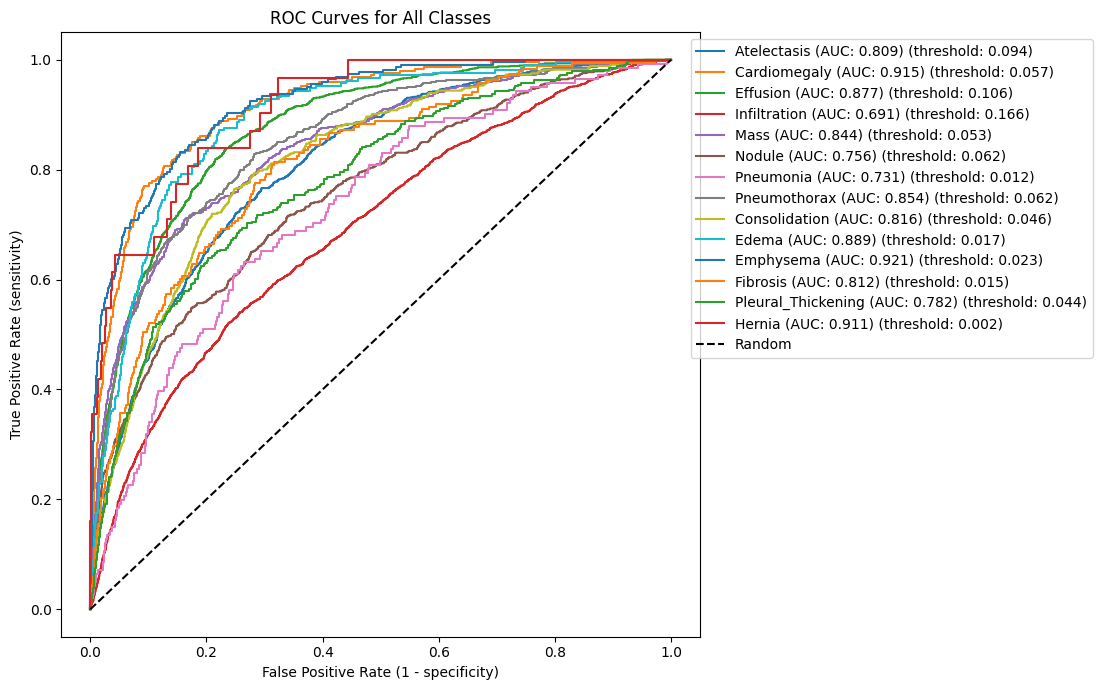

In [105]:
plot_roc_curve(Y_true, Y_probability, PREDICTABLE_CLASSES)

<h3>3.2 Obliczanie przedziałów ufności</h3>
<p>
  Nasze dane to tylko próbka rzeczywistości, dlatego wszystkie obliczone metryki są jedynie przybliżeniem prawdziwych wartości.
</p>
<p>
  Żeby uwzględnić niepewność związaną z tym próbkowaniem, korzysta się z przedziałów ufności. Na przykład 95% przedział ufności oznacza, że w 95 na 100 przypadków taki przedział zawiera rzeczywistą wartość parametru.
</p>
<p>
  W przypadku bardziej złożonych metryk, takich jak AUC, trudno wyznaczyć przedział ufności analitycznie. W takich sytuacjach pomaga metoda <em>bootstrap</em>, która polega na wielokrotnym losowaniu z zamianą z oryginalnego zbioru danych.
</p>
<p>
  Dla każdej takiej próby obliczamy wartość metryki, co pozwala oszacować, jak bardzo może się ona zmieniać.
</p>
<p>
  W przykładzie kodu zastosowano próbkowanie warstwowe, aby zachować proporcje klas w każdej próbce.
</p>

In [106]:
def bootstrap_auc(y, prob, class_names, bootstraps=100, fold_size=1000):
    statistics = np.zeros((len(class_names), bootstraps))

    for c in range(len(class_names)):
        df = pd.DataFrame(columns=["y", "pred"])
        df.loc[:, "y"] = y[:, c]
        df.loc[:, "pred"] = prob[:, c]
        df_pos = df[df.y == 1]
        df_neg = df[df.y == 0]
        prevalence = len(df_pos) / len(df)
        for i in range(bootstraps):
            pos_sample = df_pos.sample(n=int(fold_size * prevalence), replace=True)
            neg_sample = df_neg.sample(
                n=int(fold_size * (1 - prevalence)), replace=True
            )
            y_sample = np.concatenate([pos_sample.y.values, neg_sample.y.values])
            pred_sample = np.concatenate(
                [pos_sample.pred.values, neg_sample.pred.values]
            )
            score = roc_auc_score(y_sample, pred_sample)
            statistics[c][i] = score
    return statistics


def print_confidence_intervals(statistics, class_names):
    confidence_intervals = [
        {
            "Class name": class_name,
            "Mean AUC (CI 5%-95%)": f"{np.mean(class_stats):.2f} ({np.quantile(class_stats, 0.05):.2f}-{np.quantile(class_stats, 0.95):.2f})",
        }
        for class_name, class_stats in zip(class_names, statistics)
    ]
    return pd.DataFrame(confidence_intervals)



Przedziały ufności dla każdej klasy:

In [107]:
statistics = bootstrap_auc(Y_true, Y_probability, PREDICTABLE_CLASSES)
print_confidence_intervals(statistics, PREDICTABLE_CLASSES)

,Class name,Mean AUC (CI 5%-95%)
0,Atelectasis,0.81 (0.78-0.84)
1,Cardiomegaly,0.92 (0.87-0.96)
2,Effusion,0.88 (0.85-0.90)
3,Infiltration,0.69 (0.65-0.72)
4,Mass,0.84 (0.78-0.89)
5,Nodule,0.75 (0.69-0.82)
6,Pneumonia,0.74 (0.60-0.87)
7,Pneumothorax,0.86 (0.81-0.90)
8,Consolidation,0.82 (0.75-0.87)
9,Edema,0.89 (0.82-0.94)


<h3> 3.3 Krzywa zależności Precision - Recall (lub PPV - Sensitivity) </h4>

In [108]:
def plot_precision_recall_curve(y, prob, class_names):
    plt.figure(figsize=(10, 7))
    for class_index in range(len(class_names)):
        precision, recall, _ = precision_recall_curve(
            y[:, class_index], prob[:, class_index]
        )
        average_precision = average_precision_score(
            y[:, class_index], prob[:, class_index]
        )
        plt.step(
            recall,
            precision,
            where="post",
            label=f"{class_names[class_index]} [Avg.: {average_precision:.3f}]",
        )
    plt.xlabel("Recall (Sensitivity)")
    plt.ylabel("Precision")
    plt.ylim([0.0, 1.05])
    plt.xlim([0.0, 1.0])
    plt.legend(loc="upper center", bbox_to_anchor=(1.3, 1), fancybox=True, ncol=1)

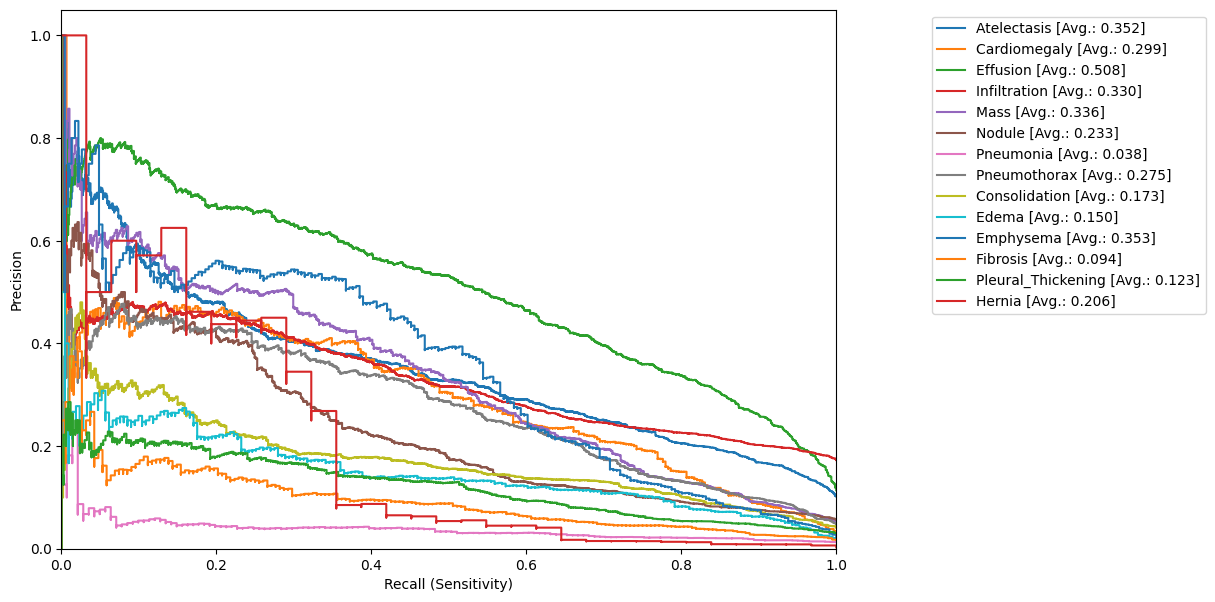

In [109]:
plot_precision_recall_curve(Y_true, Y_probability, PREDICTABLE_CLASSES)

<h3> 3.4 Kalibracja</h4>

  <p>
    Podczas klasyfikacji chcemy nie tylko przewidzieć klasę, ale też znać <strong>prawdopodobieństwo</strong> – czyli jak bardzo model jest pewny swojej decyzji.
  </p>
  <p>
    Aby sprawdzić, czy te przewidywane prawdopodobieństwa są wiarygodne, tworzy się <strong>krzywą kalibracyjną</strong>.
  </p>
  <p>
    Jak to działa:
    <ul>
      <li>Dzielimy przewidywane prawdopodobieństwa (np. 0–1) na kilka przedziałów, np. 5.</li>
      <li>Dla każdego przedziału obliczamy:
        <ul>
          <li><strong>Średnie przewidywane prawdopodobieństwo</strong> (oś X),</li>
          <li><strong>Rzeczywisty odsetek trafień</strong> – ile razy model faktycznie miał rację (oś Y).</li>
        </ul>
      </li>
      <li>Rysujemy te punkty na wykresie.</li>
    </ul>
  </p>
  <p>
    Jeśli model jest dobrze skalibrowany, punkty będą blisko linii <code>y = x</code>. To znaczy, że np. przy przewidywanym 70% model faktycznie ma rację w ok. 70% przypadków.
  </p>

In [110]:
def plot_calibration_curve(y, prob):
    plt.figure(figsize=(20, 20))
    for class_index in range(len(PREDICTABLE_CLASSES)):
        plt.subplot(4, 4, class_index + 1)
        fraction_of_positives, mean_predicted_value = calibration_curve(
            y[:, class_index], prob[:, class_index], n_bins=20
        )
        plt.plot([0, 1], [0, 1], linestyle="--")
        plt.plot(mean_predicted_value, fraction_of_positives, marker=".")
        plt.xlabel("Predicted Value")
        plt.ylabel("Fraction of Positives")
        plt.title(PREDICTABLE_CLASSES[class_index])
    plt.tight_layout()
    plt.show()

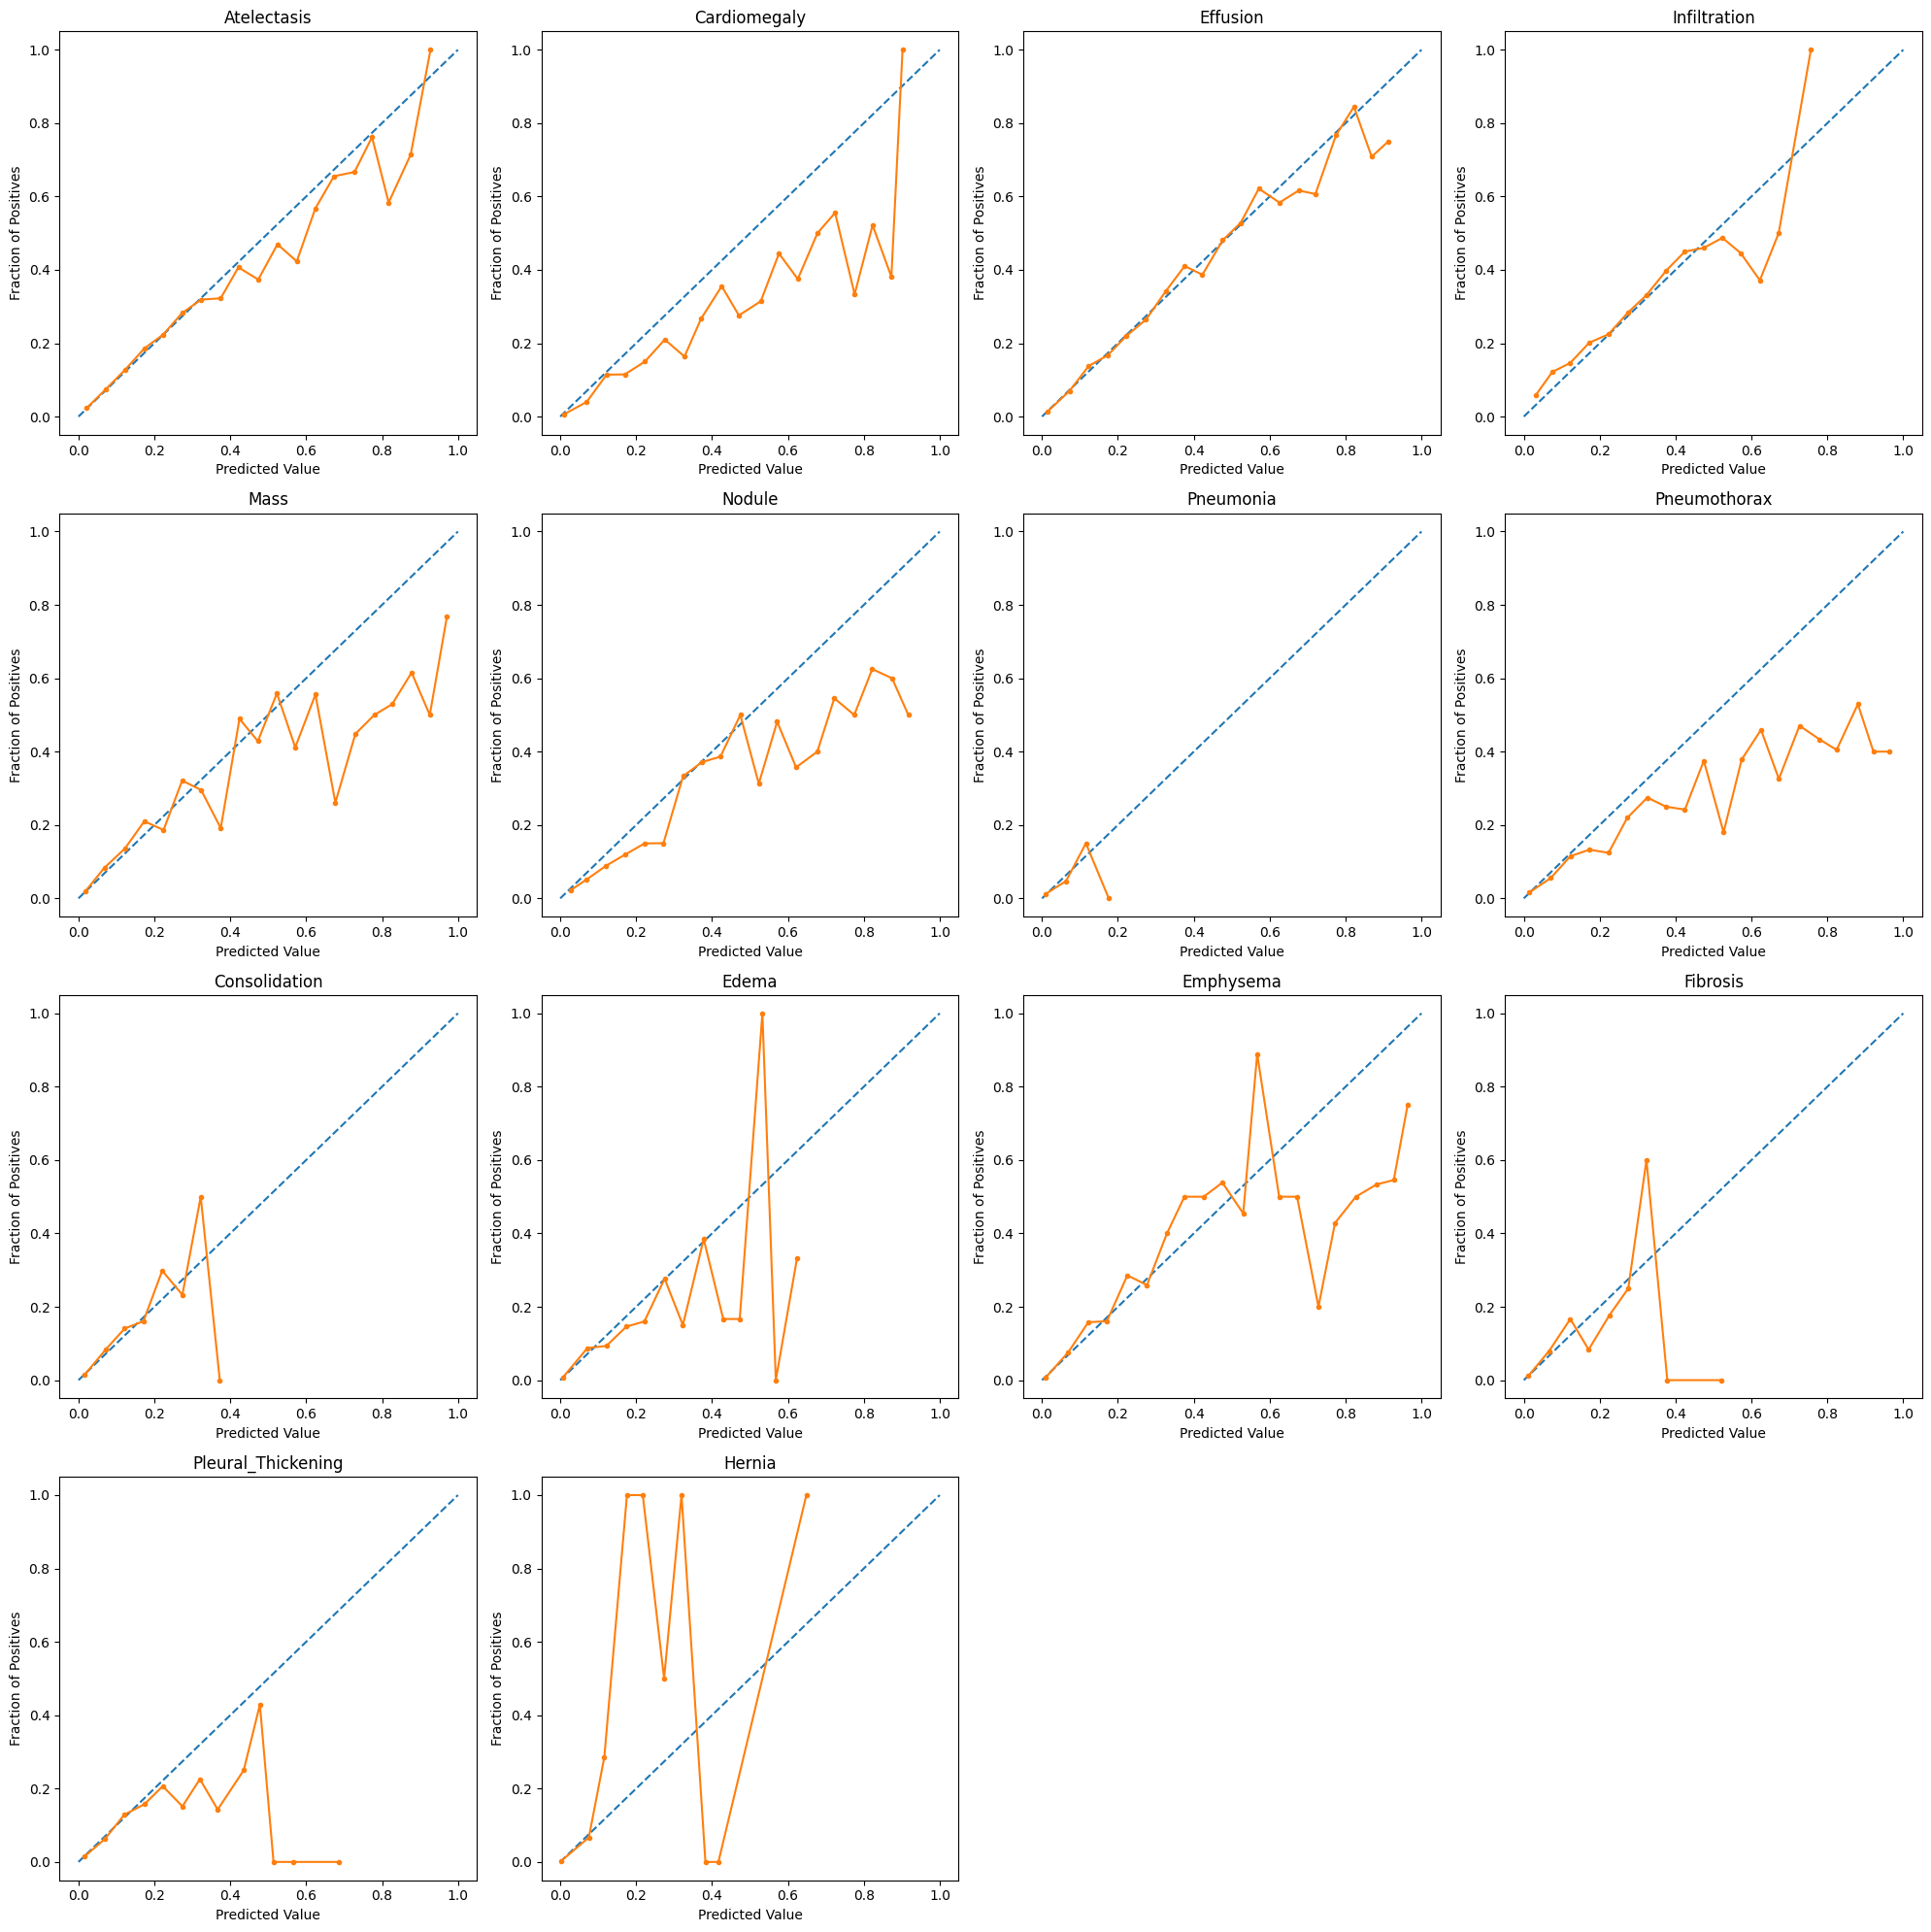

In [111]:
plot_calibration_curve(Y_true, Y_probability)

<p>
Jeśli model nie jest dobrze skalibrowany, można to poprawić za pomocą <strong>skalowania Platta</strong>. To metoda, która dopasowuje funkcję regresji logistycznej do wyników modelu, by przewidywane wartości lepiej oddawały rzeczywistość.
</p>
<p>
Do jej nauki używamy danych treningowych, a potem stosujemy ją na danych testowych.
</p>